In [4]:
from pathlib import Path

# หาโฟลเดอร์ archive ที่มี Image และ Mask โดยไม่ต้อง mount Google Drive
cwd = Path.cwd()
candidates = [
    cwd / 'archive',
    cwd,
    cwd.parent / 'archive',
    Path('/content/archive'),
    Path('/content'),
]
DATASET_DIR = next(
    (
        candidate.resolve()
        for candidate in candidates
        if (candidate / 'Image').is_dir() and (candidate / 'Mask').is_dir()
    ),
    None,
)

if DATASET_DIR is None:
    raise FileNotFoundError(
        f"ไม่พบโฟลเดอร์ archive ที่มี Image และ Mask จาก {cwd} "
        "กรุณาวางโฟลเดอร์ archive ไว้ใน working directory หรือกำหนด path ให้ถูกต้อง"
    )

OUTPUT_DIR = cwd / 'FloodVision_AI'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset folder:', DATASET_DIR)
print('Image folder exists:', (DATASET_DIR / 'Image').is_dir())
print('Mask folder exists:', (DATASET_DIR / 'Mask').is_dir())
print('Output folder:', OUTPUT_DIR)


Dataset folder: C:\Users\nisaz\Desktop\flood\archive
Image folder exists: True
Mask folder exists: True
Output folder: c:\Users\nisaz\Desktop\flood\archive\FloodVision_AI


In [5]:
from pathlib import Path

ARCHIVE = DATASET_DIR
print('Archive:', ARCHIVE)

for folder in (ARCHIVE / 'Image', ARCHIVE / 'Mask'):
    files = [p for p in folder.iterdir() if p.is_file()]
    print(f'{folder.name}: {len(files)} files')

for name in ('manifest.csv', 'README.md'):
    path = ARCHIVE / name
    print(f'{name}:', 'exists' if path.is_file() else 'not found')


Archive: C:\Users\nisaz\Desktop\flood\archive
Image: 3009 files
Mask: 3009 files
manifest.csv: exists
README.md: exists


In [6]:
from PIL import Image
import numpy as np

IMAGE_DIR = DATASET_DIR / 'Image'
MASK_DIR = DATASET_DIR / 'Mask'

if not IMAGE_DIR.is_dir() or not MASK_DIR.is_dir():
    raise FileNotFoundError(
        f"ต้องมีโฟลเดอร์ Image และ Mask ใน {DATASET_DIR}"
    )

# จับคู่จากชื่อไฟล์ เช่น Image/0.jpg กับ Mask/0.png
image_files = {p.stem: p for p in IMAGE_DIR.glob('*')
               if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}}
mask_files = {p.stem: p for p in MASK_DIR.glob('*')
              if p.suffix.lower() in {'.png', '.jpg', '.jpeg'}}

matched_ids = sorted(
    set(image_files) & set(mask_files),
    key=lambda x: (not x.isdigit(), int(x) if x.isdigit() else x)
)

print("Images:", len(image_files))
print("Masks:", len(mask_files))
print("Matched pairs:", len(matched_ids))
print("Images without masks:", len(set(image_files) - set(mask_files)))
print("Masks without images:", len(set(mask_files) - set(image_files)))

# ตรวจขนาดภาพและ Mask
valid_pairs = []
size_mismatches = []

for sample_id in matched_ids:
    with Image.open(image_files[sample_id]) as img:
        image_size = img.size
    with Image.open(mask_files[sample_id]) as mask:
        mask_size = mask.size

    if image_size == mask_size:
        valid_pairs.append(sample_id)
    else:
        size_mismatches.append((sample_id, image_size, mask_size))

print("\nMatched-size pairs:", len(valid_pairs))
print("Size mismatches:", len(size_mismatches))

for sample_id, img_size, mask_size in size_mismatches:
    print(f"ID {sample_id}: Image={img_size}, Mask={mask_size}")

# ดูตัวอย่าง 3 คู่
import matplotlib.pyplot as plt

for sample_id in valid_pairs[:3]:
    with Image.open(image_files[sample_id]) as img:
        image = img.convert('RGB').copy()
    with Image.open(mask_files[sample_id]) as mask:
        mask = mask.copy()

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(image)
    ax[0].set_title(f'Original Image: {sample_id}')
    ax[1].imshow(mask, cmap='gray')
    ax[1].set_title('Ground Truth Mask')

    for a in ax:
        a.axis('off')
    plt.tight_layout()
    plt.show()


ModuleNotFoundError: No module named 'PIL'

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

IMAGE_DIR = DATASET_DIR / 'Image'
MASK_DIR = DATASET_DIR / 'Mask'

IMG_SIZE = 256
SEED = 42

if not IMAGE_DIR.is_dir() or not MASK_DIR.is_dir():
    raise FileNotFoundError(
        f"ต้องมีโฟลเดอร์ Image และ Mask ใน {DATASET_DIR}"
    )

# ตรวจสอบคู่ภาพที่ขนาดตรงกัน
image_files = {
    p.stem: p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
}
mask_files = {
    p.stem: p for p in MASK_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
}

matched_ids = sorted(
    set(image_files) & set(mask_files),
    key=lambda x: (not x.isdigit(), int(x) if x.isdigit() else x)
)

valid_pairs = []
for sample_id in matched_ids:
    with Image.open(image_files[sample_id]) as img, \
         Image.open(mask_files[sample_id]) as mask:
        if img.size == mask.size:
            valid_pairs.append(sample_id)

print("Valid image-mask pairs:", len(valid_pairs))
print("Excluded pairs:", len(matched_ids) - len(valid_pairs))

# โหลดและปรับขนาดภาพ
X, Y = [], []

for sample_id in valid_pairs:
    with Image.open(image_files[sample_id]) as img:
        img = img.convert('RGB').resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
        )
        image = np.asarray(img, dtype=np.float32) / 255.0

    with Image.open(mask_files[sample_id]) as mask:
        mask = mask.convert('L').resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
        )
        mask = np.asarray(mask, dtype=np.uint8)

    # Binary mask: 0 = non-flood, 1 = flood
    binary_mask = (mask >= 128).astype(np.float32)
    binary_mask = np.expand_dims(binary_mask, axis=-1)

    X.append(image)
    Y.append(binary_mask)

X = np.asarray(X, dtype=np.float32)
Y = np.asarray(Y, dtype=np.float32)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Mask classes:", np.unique(Y))

# Split: 70% train, 15% validation, 15% test
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.30, random_state=SEED
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=0.50, random_state=SEED
)

print("\n===== Dataset Split =====")
print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

# แสดงตัวอย่างภาพและ Mask
fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for i in range(3):
    axes[i, 0].imshow(X_train[i])
    axes[i, 0].set_title(f"Training Image {i+1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(Y_train[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Binary Ground Truth Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    return x

def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 512)

    # Decoder
    u4 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(b)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="flood_mask"
    )(c8)

    return Model(inputs, outputs, name="FloodVision_UNet")

model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "FloodVision_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

Sample 1: White pixels = 0.00%, Black pixels = 100.00%


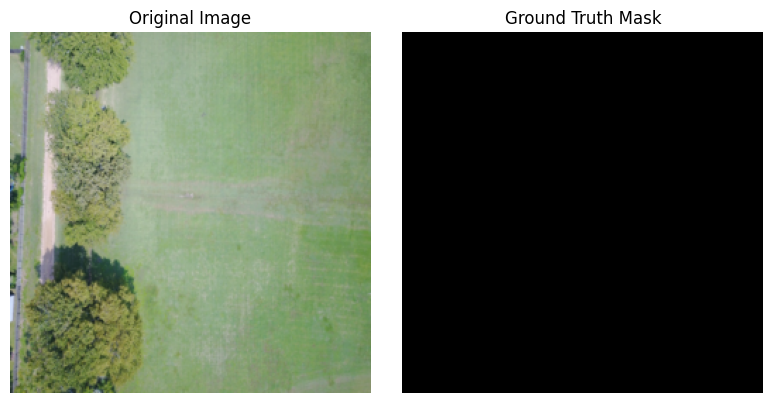

Sample 2: White pixels = 0.00%, Black pixels = 100.00%


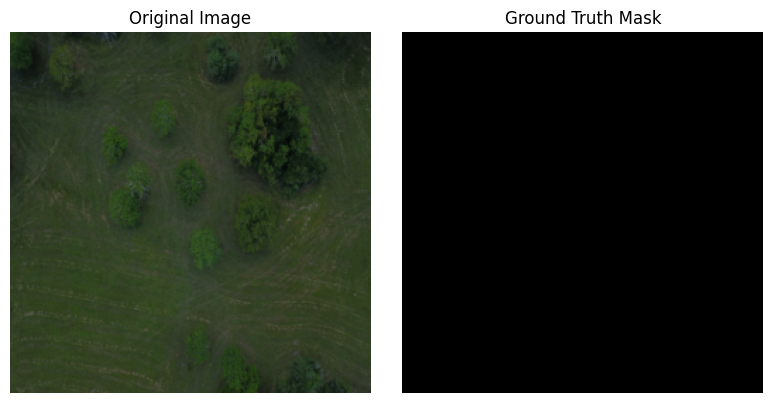

Sample 3: White pixels = 0.00%, Black pixels = 100.00%


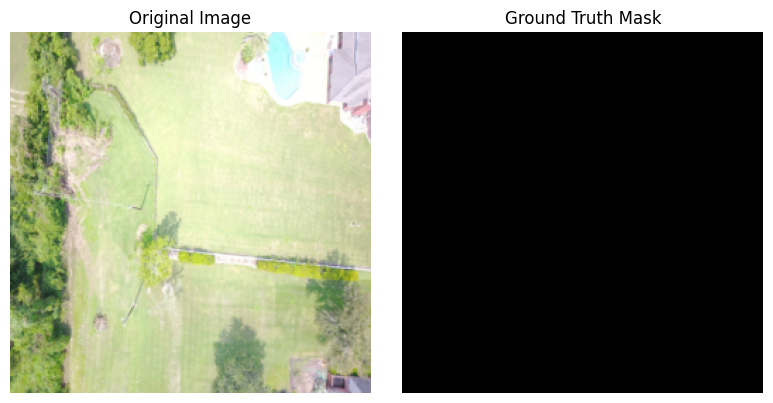

Sample 4: White pixels = 6.10%, Black pixels = 93.90%


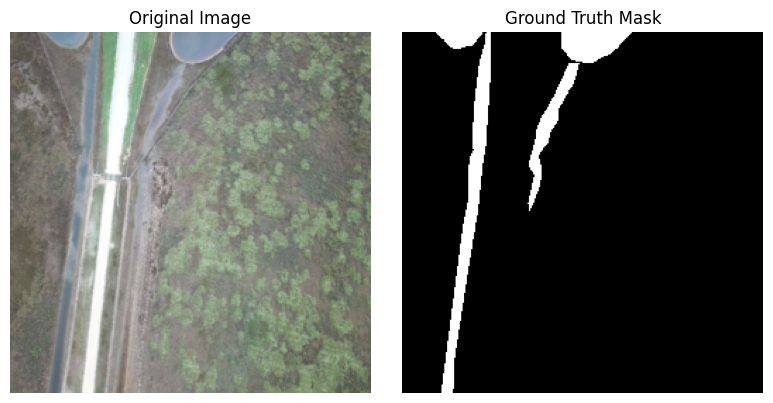

Sample 5: White pixels = 21.43%, Black pixels = 78.57%


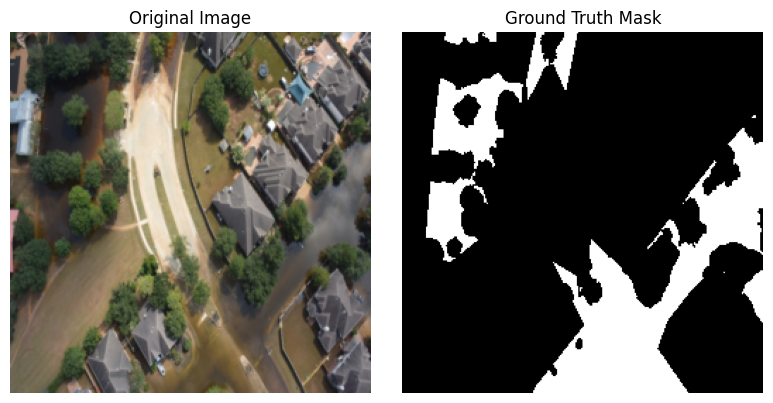

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# ดูตัวอย่างภาพและ Mask พร้อมพื้นที่สีขาว
for i in range(min(5, len(X_train))):
    image = X_train[i]
    mask = Y_train[i, :, :, 0]

    print(
        f"Sample {i+1}: "
        f"White pixels = {np.mean(mask == 1) * 100:.2f}%, "
        f"Black pixels = {np.mean(mask == 0) * 100:.2f}%"
    )

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(image)
    ax[0].set_title("Original Image")
    ax[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title("Ground Truth Mask")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# @title Train baseline U-Net
from pathlib import Path
import tensorflow as tf

required_data = ("X_train", "Y_train", "X_val", "Y_val")
missing_data = [name for name in required_data if name not in globals()]
if missing_data:
    raise RuntimeError(
        f"ไม่พบข้อมูล {', '.join(missing_data)} กรุณารันเซลล์เตรียมข้อมูลก่อนเซลล์นี้"
    )

if "model" not in globals():
    if "model_check" in globals():
        print("พบ model_check และจะใช้โมเดลนั้นฝึกต่อ")
        model = model_check
    elif "build_unet" in globals():
        print("สร้างโมเดล U-Net ใหม่จาก build_unet()")
        model = build_unet(input_shape=(256, 256, 3))
    else:
        raise RuntimeError(
            "ไม่พบ model, model_check หรือ build_unet กรุณารันเซลล์สร้างโมเดลก่อน "
            "หรือเลือก Runtime > Run all"
        )

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

SAVE_DIR = OUTPUT_DIR
SAVE_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = SAVE_DIR / 'FloodVision_UNet_best.keras'
LAST_MODEL_PATH = SAVE_DIR / 'FloodVision_UNet_last.keras'
HISTORY_PATH = SAVE_DIR / 'training_history.csv'

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(LAST_MODEL_PATH),
        save_best_only=False,
        save_freq='epoch',
        verbose=0
    ),
    tf.keras.callbacks.CSVLogger(
        str(HISTORY_PATH),
        append=False
    )
]

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=30,
    batch_size=8,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining complete!")
print("Best model:", BEST_MODEL_PATH)
print("Latest model:", LAST_MODEL_PATH)
print("Training history:", HISTORY_PATH)


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = OUTPUT_DIR
BEST_MODEL_PATH = PROJECT_DIR / 'FloodVision_UNet_best.keras'

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"ไม่พบไฟล์โมเดล {BEST_MODEL_PATH} กรุณารันเซลล์ฝึกโมเดลก่อน"
    )

best_model = tf.keras.models.load_model(str(BEST_MODEL_PATH), compile=False)

# ใช้ Test Set ซึ่งไม่ได้ใช้ฝึกโมเดล
predictions = best_model.predict(X_test, verbose=1)

# แปลงค่าความน่าจะเป็นเป็น Binary Mask
pred_masks = (predictions >= 0.5).astype(np.uint8)

# แสดงตัวอย่าง 5 ภาพ
n = min(5, len(X_test))
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title('Original Image')

    axes[i, 1].imshow(Y_test[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
    axes[i, 1].set_title('Ground Truth Mask')

    axes[i, 2].imshow(pred_masks[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
    axes[i, 2].set_title('Predicted Mask')

    for j in range(3):
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()


Prediction min: 0.42598700523376465
Prediction max: 0.5570429563522339
Prediction mean: 0.5000390410423279
Prediction std: 0.02093472145497799
Threshold 0.3: Flood pixels = 100.00%
Threshold 0.5: Flood pixels = 50.84%
Threshold 0.7: Flood pixels = 0.00%


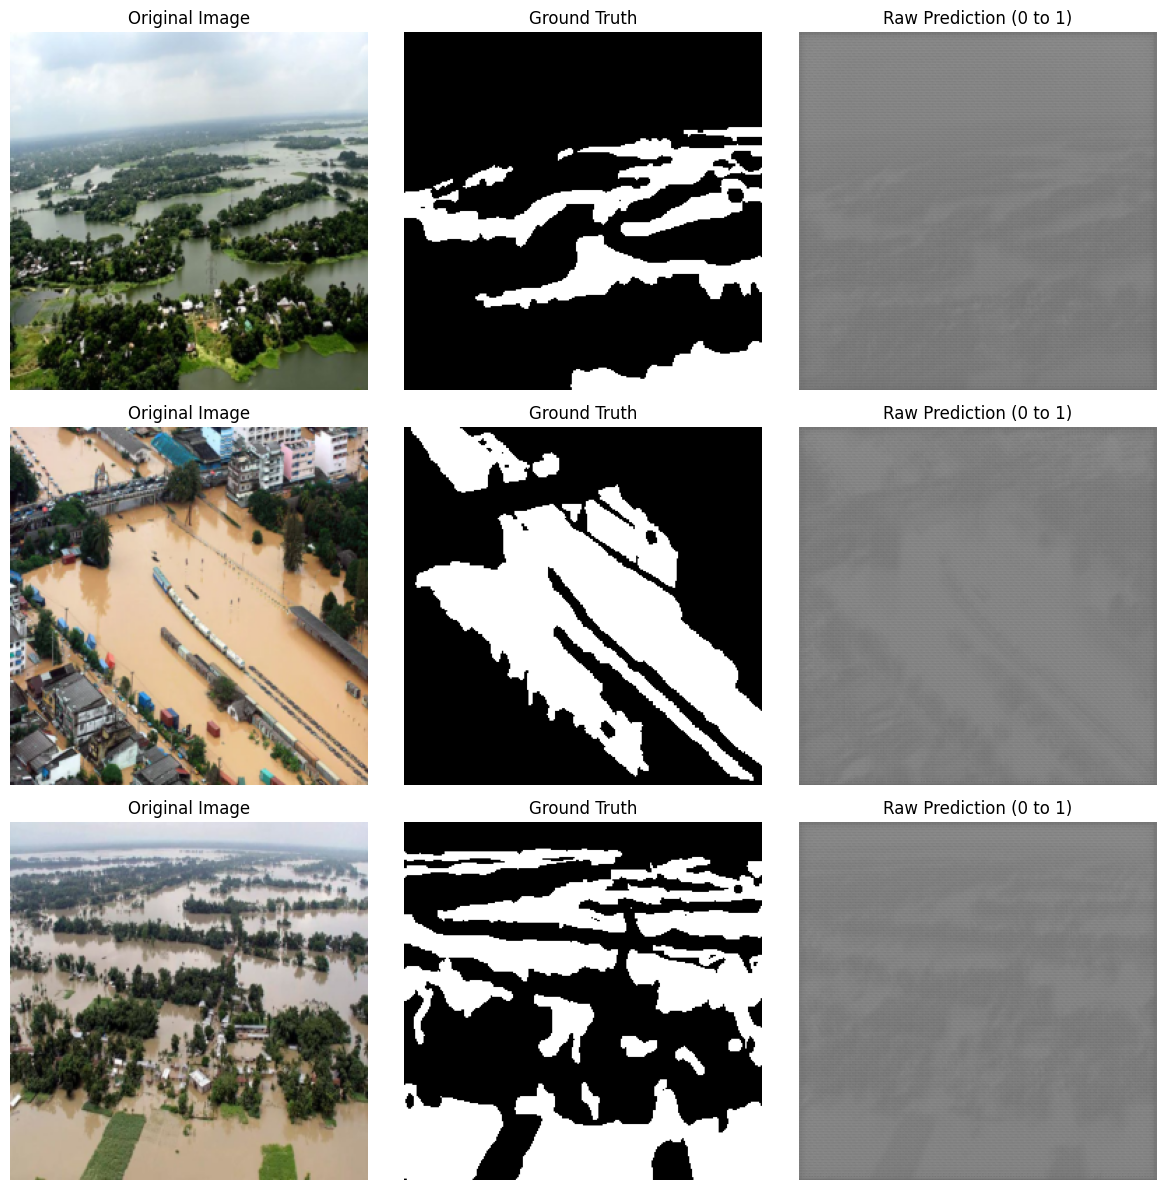

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ตรวจค่าความน่าจะเป็นที่โมเดลทำนาย
probs = best_model.predict(X_test[:5], verbose=0)

print("Prediction min:", float(probs.min()))
print("Prediction max:", float(probs.max()))
print("Prediction mean:", float(probs.mean()))
print("Prediction std:", float(probs.std()))

for threshold in [0.3, 0.5, 0.7]:
    flood_percent = (probs >= threshold).mean() * 100
    print(f"Threshold {threshold}: Flood pixels = {flood_percent:.2f}%")

# แสดงค่าทำนายแบบต่อเนื่อง ก่อนตัดเป็นขาวดำ
n = min(3, len(probs))
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        Y_test[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        probs[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 2].set_title("Raw Prediction (0 to 1)")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


===== Prediction Comparison =====
Train prediction mean: 0.5000511407852173
Train prediction std: 0.02044631913304329
Test prediction mean: 0.5000390410423279
Test prediction std: 0.02093472145497799

===== Ground Truth Flood Ratios =====
Train flood pixels: 42.0963020324707 %
Validation flood pixels: 38.26515579223633 %
Test flood pixels: 38.43752670288086 %


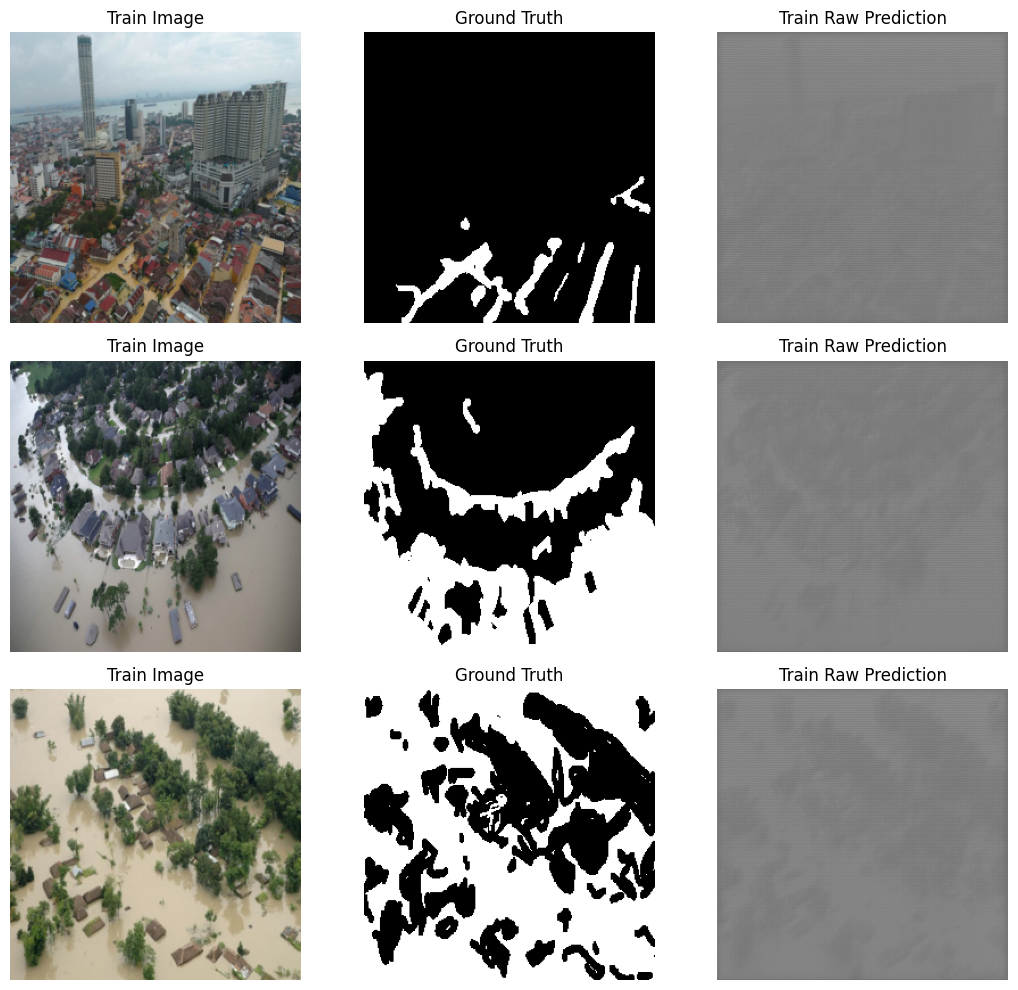

In [ ]:

# เปรียบเทียบการทำนาย Train และ Test
train_probs = best_model.predict(X_train[:5], verbose=0)
test_probs = best_model.predict(X_test[:5], verbose=0)

print("===== Prediction Comparison =====")
print("Train prediction mean:", float(train_probs.mean()))
print("Train prediction std:", float(train_probs.std()))
print("Test prediction mean:", float(test_probs.mean()))
print("Test prediction std:", float(test_probs.std()))

print("\n===== Ground Truth Flood Ratios =====")
print("Train flood pixels:", float(Y_train.mean() * 100), "%")
print("Validation flood pixels:", float(Y_val.mean() * 100), "%")
print("Test flood pixels:", float(Y_test.mean() * 100), "%")

# เทียบภาพจริง, Mask จริง, ผลทำนายจาก Train
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for i in range(3):
    axes[i, 0].imshow(X_train[i])
    axes[i, 0].set_title("Train Image")

    axes[i, 1].imshow(
        Y_train[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        train_probs[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 2].set_title("Train Raw Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
import numpy as np
from pathlib import Path

# 1. Dice coefficient
def dice_coef(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    smooth = 1e-6
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    total = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    )

    dice = (2.0 * intersection + smooth) / (total + smooth)
    return tf.reduce_mean(dice)


# 2. BCE + Dice Loss
def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    bce = tf.reduce_mean(bce)

    dice_loss = 1.0 - dice_coef(y_true, y_pred)
    return bce + dice_loss


# 3. สร้างโมเดลใหม่จากน้ำหนักเริ่มต้น
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model = build_unet(input_shape=(256, 256, 3))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[
        dice_coef,
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="flood_iou"
        )
    ]
)

# 4. บันทึกโมเดลใหม่แยกจากไฟล์เดิม
SAVE_DIR = OUTPUT_DIR
SAVE_DIR.mkdir(parents=True, exist_ok=True)

NEW_BEST_PATH = SAVE_DIR / 'FloodVision_UNet_BCEDice_best.keras'
NEW_LAST_PATH = SAVE_DIR / 'FloodVision_UNet_BCEDice_last.keras'

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(NEW_BEST_PATH),
        monitor='val_dice_coef',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(NEW_LAST_PATH),
        save_best_only=False,
        save_freq='epoch',
        verbose=0
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_dice_coef',
        mode='max',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]

# 5. ฝึกโมเดล
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=50,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining finished!")
print("Best model:", NEW_BEST_PATH)
print("Latest model:", NEW_LAST_PATH)


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

MODEL_PATH = OUTPUT_DIR / 'FloodVision_UNet_BCEDice_best.keras'

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"ไม่พบไฟล์โมเดล {MODEL_PATH} กรุณารันเซลล์ฝึกโมเดล BCE+Dice ก่อน"
    )

# โหลดโมเดลที่ดีที่สุด
best_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        'bce_dice_loss': bce_dice_loss,
        'dice_coef': dice_coef
    }
)

# ประเมินผลบน Test Set
test_results = best_model.evaluate(
    X_test, Y_test, verbose=1, return_dict=True
)

print("\n===== FloodVision AI: Test Results =====")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

# คำนวณ Dice และ IoU จาก Binary Masks โดยตรง
probabilities = best_model.predict(X_test, verbose=1)
pred_masks = (probabilities >= 0.5).astype(np.uint8)
true_masks = (Y_test >= 0.5).astype(np.uint8)

intersection = np.sum(pred_masks * true_masks, axis=(1, 2, 3))
pred_area = np.sum(pred_masks, axis=(1, 2, 3))
true_area = np.sum(true_masks, axis=(1, 2, 3))
union = pred_area + true_area - intersection

dice_scores = (2 * intersection + 1e-7) / (
    pred_area + true_area + 1e-7
)
iou_scores = (intersection + 1e-7) / (union + 1e-7)

print(f"\nMean Test Dice: {dice_scores.mean():.4f}")
print(f"Mean Test IoU:  {iou_scores.mean():.4f}")

# แสดงภาพจริง / Mask จริง / Mask ที่ทำนาย
n = min(5, len(X_test))
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        true_masks[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(
        pred_masks[i, :, :, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[i, 2].set_title(
        f"Predicted Mask | Dice {dice_scores[i]:.3f}"
    )

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path
import tensorflow as tf

# ตำแหน่งไฟล์โมเดลที่เราบันทึกไว้
PROJECT_DIR = OUTPUT_DIR

BEST_MODEL_PATH = PROJECT_DIR / 'FloodVision_UNet_BCEDice_best.keras'
LAST_MODEL_PATH = PROJECT_DIR / 'FloodVision_UNet_BCEDice_last.keras'

print("===== FloodVision AI: Model Check =====")

for path in [BEST_MODEL_PATH, LAST_MODEL_PATH]:
    print(f"\nFile: {path.name}")
    print("Exists:", path.exists())

    if path.exists():
        print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

# โหลดโมเดลที่มีผล Validation Dice ดีที่สุด
if BEST_MODEL_PATH.exists():
    model_check = tf.keras.models.load_model(
        str(BEST_MODEL_PATH),
        compile=False
    )

    print("\nเปิดโมเดลสำเร็จ!")
    print("Model name:", model_check.name)
    print("Input shape:", model_check.input_shape)
    print("Output shape:", model_check.output_shape)
    print("Total parameters:", model_check.count_params())
else:
    print("\nไม่พบไฟล์โมเดล กรุณาตรวจสอบตำแหน่งบันทึกไฟล์")

In [ ]:
# ค้นหาตัวแปรที่เกี่ยวข้องกับชุดข้อมูลใน Colab
keywords = ["x_test", "y_test", "x_train", "y_train",
            "test", "mask", "image", "dataset"]

found = []

for name, value in globals().copy().items():
    if any(k in name.lower() for k in keywords):
        if not name.startswith("_"):
            try:
                shape = getattr(value, "shape", None)
                if shape is not None:
                    found.append((name, str(shape)))
            except Exception:
                pass

print("===== Dataset Variables =====")
if found:
    for name, shape in found:
        print(f"{name}: {shape}")
else:
    print("ไม่พบตัวแปรชุดข้อมูลในหน่วยความจำ")

===== Dataset Variables =====
mask: (256, 256)
image: (256, 256, 3)
binary_mask: (256, 256, 1)
X_train: (198, 256, 256, 3)
Y_train: (198, 256, 256, 1)
X_test: (43, 256, 256, 3)
Y_test: (43, 256, 256, 1)
pred_masks: (43, 256, 256, 1)
test_probs: (5, 256, 256, 1)
true_masks: (43, 256, 256, 1)


1/2 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 18s 4s/step
===== FloodVision AI: Test Results =====
Test images: 43
Mean Test Dice: 0.8045
Mean Test IoU:  0.7034
Prediction probability range: 7.700145215494558e-05 to 0.9999992251396179


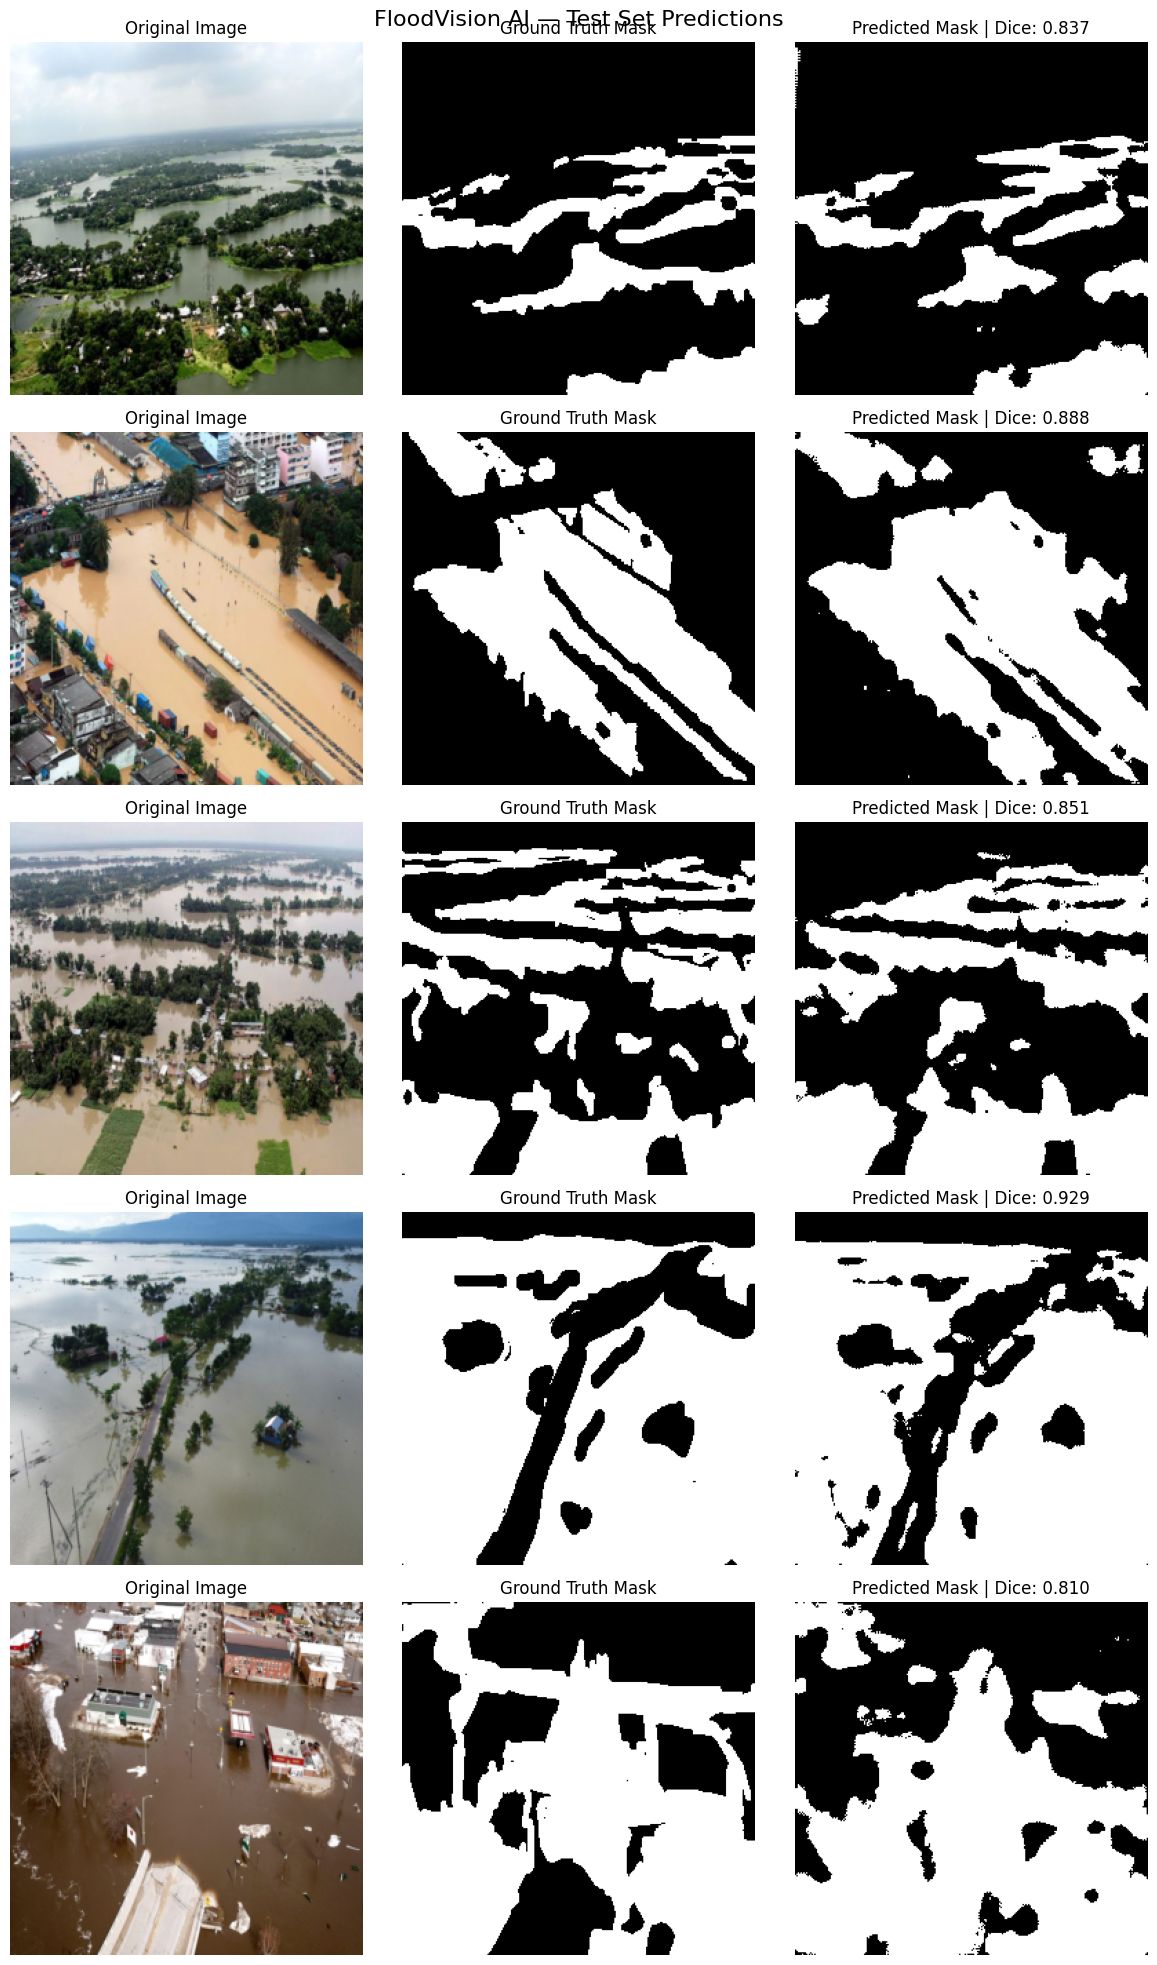

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ใช้โมเดลที่โหลดไว้แล้ว และชุด Test ที่มีอยู่จริง
pred_probs = model_check.predict(X_test, verbose=1)
pred_masks = (pred_probs >= 0.5).astype(np.uint8)
true_masks = (np.asarray(Y_test) >= 0.5).astype(np.uint8)

# คำนวณ Dice และ IoU แยกแต่ละภาพ
dice_scores = []
iou_scores = []

for i in range(len(Y_test)):
    gt = true_masks[i].astype(bool).ravel()
    pr = pred_masks[i].astype(bool).ravel()

    intersection = np.logical_and(gt, pr).sum()
    union = np.logical_or(gt, pr).sum()

    dice = (2 * intersection) / (gt.sum() + pr.sum() + 1e-7)
    iou = intersection / (union + 1e-7)

    dice_scores.append(dice)
    iou_scores.append(iou)

print("===== FloodVision AI: Test Results =====")
print("Test images:", len(X_test))
print(f"Mean Test Dice: {np.mean(dice_scores):.4f}")
print(f"Mean Test IoU:  {np.mean(iou_scores):.4f}")
print(
    "Prediction probability range:",
    float(pred_probs.min()),
    "to",
    float(pred_probs.max())
)

# แสดงภาพจริงเทียบกับ Mask จริงและ Mask ที่โมเดลทำนาย
n = min(5, len(X_test))
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    img = np.asarray(X_test[i])
    gt = true_masks[i].squeeze()
    pred = pred_masks[i].squeeze()

    if img.max() > 1:
        img = img / 255.0

    img = np.clip(img, 0, 1)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(
        f"Predicted Mask | Dice: {dice_scores[i]:.3f}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("FloodVision AI — Test Set Predictions", fontsize=16)
plt.tight_layout()
plt.show()
